# 06 · Long daily study: does Reddit predict tomorrow's gold move, 2022–2026?

The hourly study (`04_model.ipynb`) tested on **124 hours from one week**, too few to tell a real effect
from luck. Here the question moves to **days** and the history to **Jan 2022 → Oct 2 2026**:

* **Reddit:** r/Gold, r/Silverbugs and keyword-filtered r/investing, backfilled from Arctic Shift
  (`python -m collector.history_backfill`). Same cleaning, language filter, de-duplication and VADER score
  as the live collector. *VADER is not validated against our hand labels* (see `02_features.ipynb`), so mood
  features come from an unvalidated scorer. **Chatter** features (how many posts) need no scorer at all.
* **Market:** the Bloomberg terminal pull (`python -m processing.bloomberg`, git-ignored, licensed): spot gold
  (XAU), dollar index, 10-year real yield, gold volatility (GVZ), VIX, S&P 500, GLD+IAU ETF flows and
  Bloomberg's news sentiment for five gold miners.
* **Table:** `python -m processing.daily` → `data/bbg/daily_features.parquet`, one row per trading day.

**Timing (pitfalls #34–#36).** Bloomberg's daily gold close is New York 17:00 (21:00 UTC in summer). Reddit day
*d* is every post up to **20:00 UTC on d**, so it is complete before that close. **Target:** does gold close
higher on d+1 than on d? ETF flows and miner news have no published cut-off, so they are lagged a day.

**Walk-forward test.** Train on everything before a month, predict that month, add it to the training data,
repeat. That is about 940 test days from Jan 2023 → Oct 2026, every prediction made only with the past.

**Models (supervised only):**
1 majority class · 2 logistic, gold returns only · **3 logistic, market baseline** (what professionals already
see) · 7 logistic, market + Reddit mood + chatter · 8 decision tree (depth 3), market + mood + chatter ·
9 logistic, market + chatter only (no sentiment scorer).

### Success criteria, fixed before any results were seen
Reddit "adds something" **only if one model among 7, 8, 9 meets both**:

* **A. Better than the market baseline by more than luck:** more test days right than model 3, exact McNemar
  p **< 0.004** (Bonferroni: 13 Reddit models tried in the project so far).
* **B. Robust:** the same model also beats model 3 in **both halves** of the test period (2023–24 and 2025–26)
  **and** with **quarterly** instead of monthly refits. For the tree (8), it must also beat model 3 at depth 2
  **and** depth 4.

If no model meets both, the answer is: *over ~4 years of daily data, Reddit adds nothing measurable to what
the market already shows.*

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
WINDOW = ("2026-09-08", "2026-10-05T16:00")  # frozen collection window (handoff §2)

from processing.daily import (DAILY_CHATTER_FEATURES, DAILY_MARKET_FEATURES, DAILY_MOOD_FEATURES,
                              DAILY_PRICE_FEATURES)
daily = pd.read_parquet("data/bbg/daily_features.parquet")
posts = pd.read_parquet("data/clean/history_posts.parquet")
print(f"{len(posts):,} Reddit posts backfilled, {posts['created_utc'].min()[:10]} -> {posts['created_utc'].max()[:10]}")
print(posts.groupby("subreddit").size().to_string())
print(f"\n{len(daily)} trading days {daily.index.min():%Y-%m-%d} -> {daily.index.max():%Y-%m-%d}; "
      f"{int(daily['post_count'].sum()):,} de-duplicated posts assigned; gold up on {daily['up'].mean():.1%} of days")

190,541 Reddit posts backfilled, 2021-12-01 -> 2026-10-05
subreddit
Gold           77521
Silverbugs    109077
investing       3943

1228 trading days 2022-01-03 -> 2026-10-02; 184,478 de-duplicated posts assigned; gold up on 53.4% of days


## 1. Checks: the backfill is complete and the day cut-off is safe

In [2]:
stats = pd.read_csv("data/clean/history/_stats.csv")
print("Posts kept per subreddit-month (min / median / max):")
print(stats.groupby("subreddit")["ok"].agg(["min", "median", "max"]).to_string())
assert (stats.loc[stats["subreddit"] != "investing", "ok"] > 0).all(), "a month with no posts: backfill gap"

# Bloomberg's daily XAU close should equal the hourly spot price at 21:00 UTC (NY 17:00 summer time).
spot = pd.read_parquet("data/bbg/xau_spot_hourly.parquet").set_index("bucket_utc")["xau_usd"]
close = pd.read_parquet("data/bbg/market_daily.parquet")["XAU_PX_LAST"]
match = {}
for h in [19, 20, 21, 22]:
    at = (close.index + pd.Timedelta(hours=h)).tz_localize("UTC")
    both = pd.DataFrame({"close": close.to_numpy(), "spot": spot.reindex(at).to_numpy()}).dropna()
    match[f"{h}:00 UTC"] = f"{((both['close'] - both['spot']).abs() < 0.01).mean():.0%} of {len(both)} days identical"
print(pd.Series(match).to_string())
print("Reddit cut-off: 20:00 UTC, one hour before the earliest close time.")

Posts kept per subreddit-month (min / median / max):
            min  median   max
subreddit                    
Gold        225  1191.0  3900
Silverbugs  193  1681.0  7803
investing     3    54.0   254


19:00 UTC     0% of 46 days identical
20:00 UTC     2% of 46 days identical
21:00 UTC    87% of 45 days identical
22:00 UTC     9% of 35 days identical
Reddit cut-off: 20:00 UTC, one hour before the earliest close time.


## 2. Reddit and gold, four years at a glance

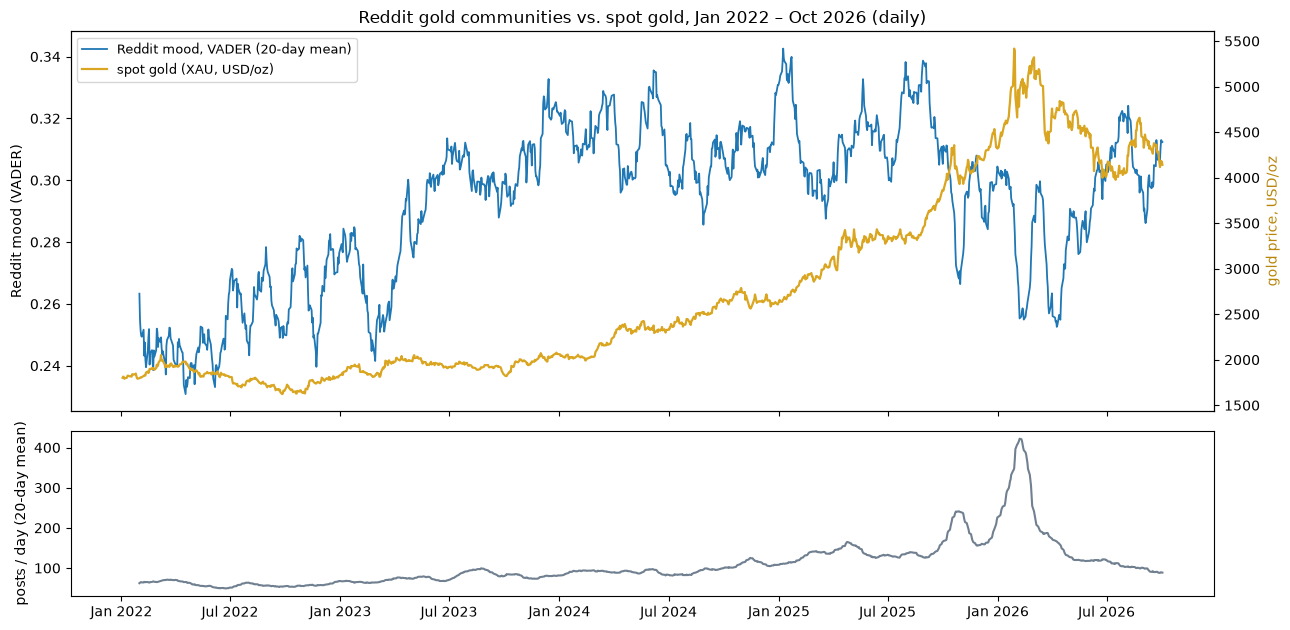

In [3]:
import matplotlib.dates as mdates
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(13, 6.4), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax1.plot(daily.index, daily["mean_sentiment"].rolling(20).mean(), color="tab:blue", lw=1.3,
         label="Reddit mood, VADER (20-day mean)")
ax1.set_ylabel("Reddit mood (VADER)")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily["xau_close"], color="goldenrod", lw=1.6, label="spot gold (XAU, USD/oz)")
ax2.set_ylabel("gold price, USD/oz", color="darkgoldenrod")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left", fontsize=9)
ax1.set_title("Reddit gold communities vs. spot gold, Jan 2022 – Oct 2026 (daily)")
ax3.plot(daily.index, daily["posts_per_day"].rolling(20).mean(), color="slategray")
ax3.set_ylabel("posts / day (20-day mean)")
ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
fig.savefig(FIGURES / "daily_1_reddit_vs_gold.png", dpi=150, bbox_inches="tight")

## 3. Walk-forward models

In [4]:
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

REDDIT = DAILY_MARKET_FEATURES + DAILY_MOOD_FEATURES + DAILY_CHATTER_FEATURES
CHATTER = DAILY_MARKET_FEATURES + DAILY_CHATTER_FEATURES
data = daily[daily["target_valid"]].dropna(subset=REDDIT).copy()   # drops the warm-up weeks only
data["y"] = data["up"].astype(int)
TEST_START, HALF = pd.Timestamp("2023-01-01"), pd.Timestamp("2025-01-01")
print(f"{len(data)} usable days from {data.index.min():%Y-%m-%d}; "
      f"{(data.index >= TEST_START).sum()} test days from {TEST_START:%Y-%m-%d}")

M1, M2, M3 = "1 majority class", "2 logistic, gold returns only", "3 logistic, market baseline"
M7, M8, M9 = ("7 logistic, market + Reddit mood + chatter", "8 decision tree, market + Reddit mood + chatter",
              "9 logistic, market + chatter (no scorer)")
REDDIT_MODELS = [M7, M8, M9]

def make_models(depth=3):
    logit = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return {M1: (DummyClassifier(strategy="most_frequent"), []), M2: (logit(), DAILY_PRICE_FEATURES),
            M3: (logit(), DAILY_MARKET_FEATURES), M7: (logit(), REDDIT),
            M8: (DecisionTreeClassifier(max_depth=depth, random_state=0), REDDIT), M9: (logit(), CHATTER)}

def walk_forward(data, freq="MS", depth=3):
    """Refit every model at the start of each period on all earlier days; predict that period."""
    starts = pd.date_range(TEST_START, data.index.max(), freq=freq).union([TEST_START])
    preds, last = {m: [] for m in make_models(depth)}, None
    for a, b in zip(starts, list(starts[1:]) + [data.index.max() + pd.Timedelta(days=1)]):
        train, test = data[data.index < a], data[(data.index >= a) & (data.index < b)]
        if test.empty:
            continue
        assert train.index.max() < test.index.min()
        last = make_models(depth)
        for name, (model, cols) in last.items():
            X_tr = train[cols] if cols else np.zeros((len(train), 1))
            X_te = test[cols] if cols else np.zeros((len(test), 1))
            model.fit(X_tr, train["y"])
            preds[name].append(pd.Series(model.predict(X_te), index=test.index))
    return pd.DataFrame({m: pd.concat(p) for m, p in preds.items()}), last

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def mcnemar(a, b, y):
    only_a, only_b = int(((a == y) & (b != y)).sum()), int(((b == y) & (a != y)).sum())
    return only_a, only_b, (binomtest(only_b, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0)

preds, final_models = walk_forward(data)
y = data.loc[preds.index, "y"]
rows = []
for m in preds:
    k = int((preds[m] == y).sum())
    lo, hi = wilson(k, len(y))
    rows.append({"model": m, "n_features": len(make_models()[m][1]), "n_train": int((data.index < TEST_START).sum()),
                 "n_test": len(y), "train_acc": np.nan, "test_acc": k / len(y), "ci95_low": lo, "ci95_high": hi,
                 "pred_up_share": preds[m].mean()})
results = pd.DataFrame(rows)
print("n_train = days before the first test month (it grows by a month at each refit)")
results.round(3)

1206 usable days from 2022-02-01; 968 test days from 2023-01-01


n_train = days before the first test month (it grows by a month at each refit)


,model,n_features,n_train,n_test,train_acc,test_acc,ci95_low,ci95_high,pred_up_share
0,1 majority class,0,238,968,NaN,0.537,0.506,0.568,1.000
1,"2 logistic, gold returns only",2,238,968,NaN,0.517,0.485,0.548,0.773
2,"3 logistic, market baseline",11,238,968,NaN,0.500,0.469,0.531,0.622
3,"7 logistic, market + Reddit mood + chatter",19,238,968,NaN,0.526,0.494,0.557,0.697
4,"8 decision tree, market + Reddit mood + chatter",19,238,968,NaN,0.519,0.487,0.550,0.370
5,"9 logistic, market + chatter (no scorer)",14,238,968,NaN,0.510,0.479,0.542,0.783


In [5]:
BONFERRONI = 0.004
tests = {}
for m in REDDIT_MODELS:
    oa, ob, pv = mcnemar(preds[M3], preds[m], y)
    tests[m] = (oa, ob, pv)
    print(f"{m:<50} {(preds[m] == y).mean():.1%}   vs market baseline: only baseline right {oa}, "
          f"only Reddit model right {ob}, p = {pv:.3f}")
for m in [M2, M3]:
    print(f"{m:<50} {(preds[m] == y).mean():.1%}   vs majority p = {mcnemar(preds[M1], preds[m], y)[2]:.3f}")

coef = pd.Series(final_models[M7][0][-1].coef_[0], index=REDDIT)
print("\nModel 7, last refit: coefficients per 1 sd (+ means higher value -> gold more likely up tomorrow)")
print(coef.sort_values(key=abs, ascending=False).round(3).to_string())

7 logistic, market + Reddit mood + chatter         52.6%   vs market baseline: only baseline right 107, only Reddit model right 132, p = 0.120
8 decision tree, market + Reddit mood + chatter    51.9%   vs market baseline: only baseline right 234, only Reddit model right 252, p = 0.441
9 logistic, market + chatter (no scorer)           51.0%   vs market baseline: only baseline right 93, only Reddit model right 103, p = 0.520
2 logistic, gold returns only                      51.7%   vs majority p = 0.200
3 logistic, market baseline                        50.0%   vs majority p = 0.067

Model 7, last refit: coefficients per 1 sd (+ means higher value -> gold more likely up tomorrow)
log_posts_per_day_lag1    0.252
spx_ret_1d                0.169
bullish_ratio            -0.154
xau_ret_1d               -0.137
gvz_level                -0.134
mean_sentiment            0.120
sent_roll_mean_5d        -0.101
mean_sentiment_lag1       0.090
bearish_ratio            -0.089
gvz_chg_1d             

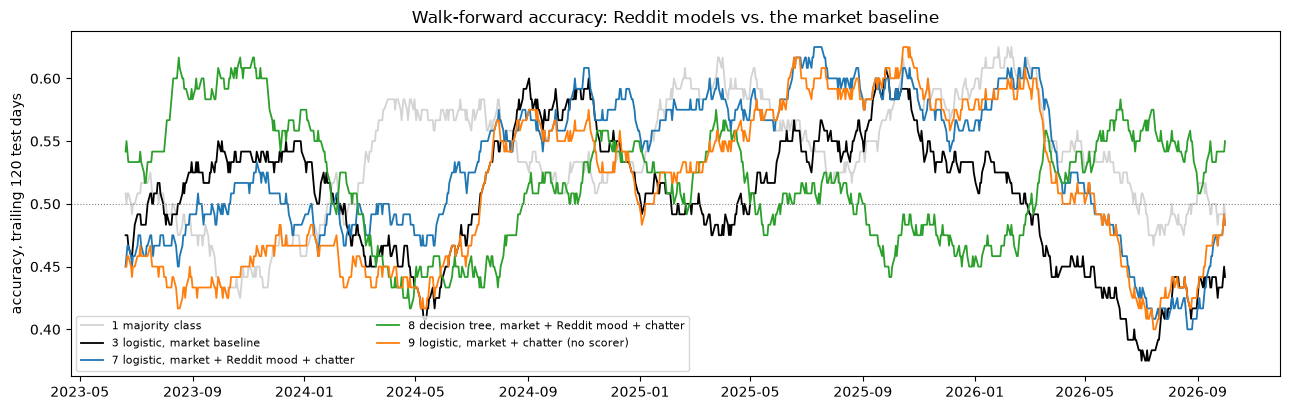

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.2))
for m, colour in [(M1, "lightgray"), (M3, "black"), (M7, "tab:blue"), (M8, "tab:green"), (M9, "tab:orange")]:
    ax.plot(preds.index, (preds[m] == y).astype(float).rolling(120).mean(), label=m, color=colour, lw=1.3)
ax.axhline(0.5, color="gray", ls=":", lw=0.8)
ax.set_ylabel("accuracy, trailing 120 test days")
ax.set_title("Walk-forward accuracy: Reddit models vs. the market baseline")
ax.legend(fontsize=8, ncol=2, loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES / "daily_2_walkforward_accuracy.png", dpi=150, bbox_inches="tight")

## 4. Robustness (criterion B)

In [7]:
def acc(p, idx):
    return (p.loc[idx] == y.loc[idx]).mean()

halves = {"2023–24": preds.index[preds.index < HALF], "2025–26": preds.index[preds.index >= HALF]}
q_preds, _ = walk_forward(data, freq="QS")
depth_preds = {d: walk_forward(data, depth=d)[0] for d in [2, 4]}
rob = []
for m in REDDIT_MODELS:
    row = {"model": m}
    for h, idx in halves.items():
        row[f"{h} model / baseline"] = f"{acc(preds[m], idx):.1%} / {acc(preds[M3], idx):.1%}"
        row[f"wins {h}"] = acc(preds[m], idx) > acc(preds[M3], idx)
    row["quarterly model / baseline"] = f"{(q_preds[m] == y).mean():.1%} / {(q_preds[M3] == y).mean():.1%}"
    row["wins quarterly"] = (q_preds[m] == y).mean() > (q_preds[M3] == y).mean()
    if m == M8:
        for d, p in depth_preds.items():
            row[f"wins depth {d}"] = (p[M8] == y).mean() > (p[M3] == y).mean()
    rob.append(row)
rob = pd.DataFrame(rob).set_index("model")
rob

,2023–24 model / baseline,wins 2023–24,2025–26 model / baseline,wins 2025–26,quarterly model / baseline,wins quarterly,wins depth 2,wins depth 4
model,,,,,,,,
"7 logistic, market + Reddit mood + chatter",51.2% / 50.4%,True,54.2% / 49.6%,True,51.5% / 50.2%,True,NaN,NaN
"8 decision tree, market + Reddit mood + chatter",51.7% / 50.4%,True,52.0% / 49.6%,True,52.2% / 50.2%,True,True,True
"9 logistic, market + chatter (no scorer)",47.9% / 50.4%,False,54.6% / 49.6%,True,50.9% / 50.2%,True,NaN,NaN


In [8]:
out = pd.read_csv("reports/model_results.csv")
DATASET = "daily 2022–26 walk-forward"
out = pd.concat([out[out["dataset"] != DATASET], results.assign(dataset=DATASET)[out.columns]], ignore_index=True)
out.round(4).to_csv("reports/model_results.csv", index=False)

## 5. Verdict against the pre-set criteria

In [9]:
verdicts = {}
for m in REDDIT_MODELS:
    oa, ob, pv = tests[m]
    a = ob > oa and pv < BONFERRONI
    b = bool(rob.loc[m].filter(like="wins").fillna(True).all())
    verdicts[m] = a and b
    print(f"{m:<50} A (p < 0.004, more right): {'PASS' if a else 'FAIL'} (p = {pv:.3f})   "
          f"B (robust): {'PASS' if b else 'FAIL'}")
print("\nOVERALL:", "Reddit adds measurable information to the market baseline" if any(verdicts.values())
      else "over ~4 years of daily data, Reddit adds nothing measurable to what the market already shows")

7 logistic, market + Reddit mood + chatter         A (p < 0.004, more right): FAIL (p = 0.120)   B (robust): PASS
8 decision tree, market + Reddit mood + chatter    A (p < 0.004, more right): FAIL (p = 0.441)   B (robust): PASS
9 logistic, market + chatter (no scorer)           A (p < 0.004, more right): FAIL (p = 0.520)   B (robust): FAIL

OVERALL: over ~4 years of daily data, Reddit adds nothing measurable to what the market already shows
